# 3. Machine Learning

**Classification:** predict `Churned`, where **1** means the customer makes no purchase in the next 90 days and **0** means they buy again.

**Steps:**
1. Split the data by time (train on the past, test on the future).
2. Build the preprocessing pipelines.
3. Compare algorithms with chronological cross-validation.
4. Handle imbalance, tune the best models and select features.
5. Test the final model once, then save it for the app.

**Main score:** F1 (balance of precision and recall), with precision, recall and accuracy also reported.

In [1]:
import numpy as np
import plotly.express as px
import pandas as pd

In [2]:
df = pd.read_csv('data/churn_data.csv', dtype= {'Customer ID': 'string'}, parse_dates= ['PredictionDate'])
df

,Customer ID,InvoiceCountLast365Days,PurchaseAmountLast365Days,DistinctProductCountLast365Days,AverageOrderValueLast365Days,DaysSinceLastPurchase,DaysSinceFirstPurchase,AverageDaysBetweenPurchases,OverdueRatio,InvoiceCountLast90Days,PurchaseAmountLast90Days,InvoiceCountLast30Days,Country,PredictionDate,Churned
0,12346,2,169.36,24,84.680000,156,274,118.00,1.322034,0.0,0.00,0.0,United Kingdom,2010-12-01,1
1,12347,1,611.53,40,611.530000,31,31,NaN,NaN,1.0,611.53,0.0,Iceland,2010-12-01,0
2,12348,1,221.16,19,221.160000,65,65,NaN,NaN,1.0,221.16,0.0,Finland,2010-12-01,0
3,12349,2,2221.14,89,1110.570000,34,216,182.00,0.186813,1.0,1152.62,0.0,Italy,2010-12-01,1
4,12351,1,300.93,21,300.930000,2,2,NaN,NaN,1.0,300.93,1.0,Unspecified,2010-12-01,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42827,18281,1,80.82,7,80.820000,81,81,NaN,NaN,1.0,80.82,0.0,United Kingdom,2011-09-01,1
42828,18282,1,100.21,7,100.210000,27,27,NaN,NaN,1.0,100.21,1.0,United Kingdom,2011-09-01,1
42829,18283,11,1145.33,205,104.120909,49,283,29.25,1.675214,4.0,436.41,0.0,United Kingdom,2011-09-01,0
42830,18284,1,411.68,27,411.680000,332,332,NaN,NaN,0.0,0.00,0.0,United Kingdom,2011-09-01,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42832 entries, 0 to 42831
Data columns (total 15 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   Customer ID                      42832 non-null  string        
 1   InvoiceCountLast365Days          42832 non-null  int64         
 2   PurchaseAmountLast365Days        42832 non-null  float64       
 3   DistinctProductCountLast365Days  42832 non-null  int64         
 4   AverageOrderValueLast365Days     42832 non-null  float64       
 5   DaysSinceLastPurchase            42832 non-null  int64         
 6   DaysSinceFirstPurchase           42832 non-null  int64         
 7   AverageDaysBetweenPurchases      26984 non-null  float64       
 8   OverdueRatio                     26984 non-null  float64       
 9   InvoiceCountLast90Days           42832 non-null  float64       
 10  PurchaseAmountLast90Days         42832 non-null  float64       
 11  

## Data Preprocessing for ML

- Split Data into Input Features and Target Variable

In [4]:
x = df.drop(['Customer ID', 'PredictionDate', 'Churned'], axis= 1)
y = df['Churned']

- Chronological Train-Test Split

Test: August-September 2011. Training: December 2010-May 2011. June and July are left out because their 90-day answers overlap the test period.

In [5]:
outcome_end = df['PredictionDate'] + pd.Timedelta(days= 90)
test_start = pd.Timestamp('2011-08-01')

train_mask = outcome_end <= test_start
test_mask = df['PredictionDate'] >= test_start

x_train, y_train = x[train_mask], y[train_mask]
x_test, y_test = x[test_mask], y[test_mask]

print('Train:', x_train.shape, '| Test:', x_test.shape)

Train: (25547, 12) | Test: (8648, 12)


In [6]:
y_train.value_counts(normalize= True)

Churned
1    0.642933
0    0.357067
Name: proportion, dtype: float64

In [7]:
y_test.value_counts(normalize= True)

Churned
1    0.536772
0    0.463228
Name: proportion, dtype: float64

In [8]:
x_train.isna().sum()

InvoiceCountLast365Days               0
PurchaseAmountLast365Days             0
DistinctProductCountLast365Days       0
AverageOrderValueLast365Days          0
DaysSinceLastPurchase                 0
DaysSinceFirstPurchase                0
AverageDaysBetweenPurchases        9310
OverdueRatio                       9310
InvoiceCountLast90Days                0
PurchaseAmountLast90Days              0
InvoiceCountLast30Days                0
Country                               0
dtype: int64

In [9]:
x_train.describe().T

,count,mean,std,min,25%,50%,75%,max
InvoiceCountLast365Days,25547.0,4.210866,7.379909,1.000000,1.00000,2.000000,5.000000,180.000000
PurchaseAmountLast365Days,25547.0,1895.336947,7702.677252,1.550000,301.26000,662.400000,1617.360000,320047.340000
DistinctProductCountLast365Days,25547.0,61.269347,82.110649,1.000000,17.00000,37.000000,76.000000,1712.000000
AverageOrderValueLast365Days,25547.0,376.997867,507.137007,1.550000,178.05000,284.850000,423.509140,14844.766667
DaysSinceLastPurchase,25547.0,112.961287,93.719874,1.000000,35.00000,89.000000,168.000000,365.000000
DaysSinceFirstPurchase,25547.0,232.514150,104.856223,1.000000,151.00000,256.000000,327.000000,365.000000
AverageDaysBetweenPurchases,16237.0,72.069369,56.472896,1.000000,33.00000,56.500000,93.666667,364.000000
OverdueRatio,16237.0,2.809584,12.443931,0.002747,0.41543,0.971429,2.123077,363.000000
InvoiceCountLast90Days,25547.0,1.064743,2.178384,0.000000,0.00000,1.000000,1.000000,80.000000
PurchaseAmountLast90Days,25547.0,479.234803,1997.584357,0.000000,0.00000,65.400000,433.430000,85836.770000


The amount and count columns have long right tails (a few very large wholesale customers), so they are scaled with the **Robust Scaler**. The day columns are bounded between 1 and 365, and InvoiceCountLast30Days has an IQR of 0, so they use the **Standard Scaler**. The two gap columns have missing values for one-day customers, filled with the **median**.

### Num Pipeline 1

In [10]:
num_cols_1 = ['DaysSinceLastPurchase', 'DaysSinceFirstPurchase', 'InvoiceCountLast30Days']
num_cols_1

['DaysSinceLastPurchase', 'DaysSinceFirstPurchase', 'InvoiceCountLast30Days']

In [11]:
# Bounded day columns and a column with IQR = 0 --> Scale with Standard Scaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

num_pipeline_1 = Pipeline(steps= [ ('Standard Scaler', standard_scaler) ])
num_pipeline_1

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Standard Scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Num Pipeline 2

In [12]:
num_cols_2 = ['InvoiceCountLast365Days', 'PurchaseAmountLast365Days', 'DistinctProductCountLast365Days',
              'AverageOrderValueLast365Days', 'AverageDaysBetweenPurchases', 'OverdueRatio',
              'InvoiceCountLast90Days', 'PurchaseAmountLast90Days']
num_cols_2

['InvoiceCountLast365Days',
 'PurchaseAmountLast365Days',
 'DistinctProductCountLast365Days',
 'AverageOrderValueLast365Days',
 'AverageDaysBetweenPurchases',
 'OverdueRatio',
 'InvoiceCountLast90Days',
 'PurchaseAmountLast90Days']

In [13]:
# Long-tailed columns, two with missing gaps --> Impute with Median and Scale with Robust Scaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

median_imputer = SimpleImputer(strategy= 'median')

robust_scaler = RobustScaler()

num_pipeline_2 = Pipeline(steps= [ ('Median Imputer', median_imputer),
                                   ('Robust Scaler', robust_scaler) ])
num_pipeline_2

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Median Imputer', ...), ('Robust Scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimato

### Cat Pipeline 1

In [14]:
cat_cols_1 = ['Country']
x_train['Country'].value_counts()

Country
United Kingdom          23485
Germany                   417
France                    305
Spain                     139
Netherlands               128
Belgium                   107
Portugal                   93
Sweden                     87
Switzerland                86
Australia                  83
Italy                      73
Channel Islands            67
Austria                    58
Denmark                    48
Japan                      43
Cyprus                     39
Finland                    38
USA                        30
Greece                     24
Norway                     22
Unspecified                21
EIRE                       18
United Arab Emirates       17
Bahrain                    12
Poland                     12
Israel                     12
Korea                      12
Canada                      8
Brazil                      7
Iceland                     6
Thailand                    6
Singapore                   6
Lithuania                   6
Ma

In [15]:
# Country --> One Hot Encoding; countries under 1% of rows are grouped together
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(min_frequency= 0.01, handle_unknown= 'infrequent_if_exist', sparse_output= False)

cat_pipeline_1 = Pipeline(steps= [ ('OHE', ohe) ])
cat_pipeline_1

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OHE', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'infrequent_if_exist'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <enco

### Assign each column to its corresponding Pipeline

In [16]:
from sklearn.compose import ColumnTransformer

preprocessing = ColumnTransformer(transformers= [
    ('Num Pipeline 1', num_pipeline_1, num_cols_1),
    ('Num Pipeline 2', num_pipeline_2, num_cols_2),
    ('Cat Pipeline 1', cat_pipeline_1, cat_cols_1)
])
preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Num Pipeline 1', ...), ('Num Pipeline 2', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_

In [17]:
preprocessing.fit_transform(x_train).shape

(25547, 15)

# Machine Learning

- Chronological Cross-Validation

Each fold trains only on months whose 90-day answer is known before the CV month.

| Fold | Train | CV |
| --- | --- | --- |
| 1 | Dec 2010 | Mar 2011 |
| 2 | Dec 2010-Jan 2011 | Apr 2011 |
| 3 | Dec 2010-Jan 2011 | May 2011 |

In [18]:
train_dates = df.loc[x_train.index, 'PredictionDate']

cv_months = ['2011-03-01', '2011-04-01', '2011-05-01']

cv_splits = []

for month in cv_months:
    month = pd.Timestamp(month)

    fold_train = train_dates + pd.Timedelta(days= 90) <= month
    fold_cv = train_dates == month

    cv_splits.append((np.flatnonzero(fold_train), np.flatnonzero(fold_cv)))

    print(month.date(), '| Train rows:', fold_train.sum(), '| CV rows:', fold_cv.sum())

2011-03-01 | Train rows: 4236 | CV rows: 4258
2011-04-01 | Train rows: 8438 | CV rows: 4316
2011-05-01 | Train rows: 8438 | CV rows: 4317


### Selecting Best Model

In [19]:
negative_class = y_train.value_counts()[0]
positive_class = y_train.value_counts()[1]

scale_pos_weight = negative_class / positive_class
scale_pos_weight

np.float64(0.5553729071537291)

In [20]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate

models = [
    ('Logistic Regression', LogisticRegression(random_state= 42, class_weight= 'balanced', max_iter= 1000)),
    ('SGD Classifier', SGDClassifier(random_state= 42, loss= 'log_loss', class_weight= 'balanced')),
    ('Gaussian NB', GaussianNB()),
    ('Decision Tree', DecisionTreeClassifier(random_state= 42, class_weight= 'balanced')),
    ('Random Forest', RandomForestClassifier(random_state= 42, class_weight= 'balanced')),
    ('XGBoost', XGBClassifier(random_state= 42, scale_pos_weight= scale_pos_weight))
]

for model in models:

    model_pipeline = Pipeline(steps= [('Preprocessing', preprocessing), ('Model', model[1])])

    cv_result = cross_validate(estimator= model_pipeline,
                               X= x_train,
                               y= y_train,
                               scoring= ['accuracy', 'precision', 'recall', 'f1'],
                               cv= cv_splits,
                               return_train_score= True,
                               n_jobs= -1
                               )

    print(model[0])

    print(f"Train Accuracy: {cv_result['train_accuracy'].mean() * 100:.2f}%")
    print(f"CV Accuracy: {cv_result['test_accuracy'].mean() * 100:.2f}%")

    print(f"Train Precision: {cv_result['train_precision'].mean() * 100:.2f}%")
    print(f"CV Precision: {cv_result['test_precision'].mean() * 100:.2f}%")

    print(f"Train Recall: {cv_result['train_recall'].mean() * 100:.2f}%")
    print(f"CV Recall: {cv_result['test_recall'].mean() * 100:.2f}%")

    print(f"Train F1: {cv_result['train_f1'].mean() * 100:.2f}%")
    print(f"CV F1: {cv_result['test_f1'].mean() * 100:.2f}%")

    print('-' * 50)

Logistic Regression
Train Accuracy: 73.80%
CV Accuracy: 74.27%
Train Precision: 83.12%
CV Precision: 76.21%
Train Recall: 76.32%
CV Recall: 85.25%
Train F1: 79.57%
CV F1: 80.48%
--------------------------------------------------


SGD Classifier
Train Accuracy: 68.70%
CV Accuracy: 68.90%
Train Precision: 78.13%
CV Precision: 71.97%
Train Recall: 74.21%
CV Recall: 81.87%
Train F1: 76.08%
CV F1: 76.58%
--------------------------------------------------


Gaussian NB
Train Accuracy: 73.69%
CV Accuracy: 68.93%
Train Precision: 74.00%
CV Precision: 67.70%
Train Recall: 93.50%
CV Recall: 95.78%
Train F1: 82.62%
CV F1: 79.32%
--------------------------------------------------


Decision Tree
Train Accuracy: 99.98%
CV Accuracy: 66.75%
Train Precision: 100.00%
CV Precision: 70.61%
Train Recall: 99.98%
CV Recall: 79.75%
Train F1: 99.99%
CV F1: 74.90%
--------------------------------------------------


Random Forest
Train Accuracy: 99.85%
CV Accuracy: 73.46%
Train Precision: 100.00%
CV Precision: 75.18%
Train Recall: 99.78%
CV Recall: 85.64%
Train F1: 99.89%
CV F1: 80.06%
--------------------------------------------------


XGBoost
Train Accuracy: 93.50%
CV Accuracy: 72.96%
Train Precision: 95.09%
CV Precision: 74.43%
Train Recall: 95.18%
CV Recall: 86.15%
Train F1: 95.14%
CV F1: 79.86%
--------------------------------------------------


**Result:** Logistic Regression has the best CV F1 (80.48%) and its train and CV scores are almost equal. Decision Tree, Random Forest and XGBoost score close to 100% on training but much lower on CV: they **overfit** (memorise the training data). SGD trains the same model as Logistic Regression, but less precisely.

- Poly degrees with Logistic Regression

PolynomialFeatures adds squared, cubed and interaction terms. The 15 preprocessed columns become 135 (degree 2), 815 (degree 3) and 3,875 (degree 4). A Standard Scaler after Poly keeps the large powers on one scale so Logistic Regression can converge.

In [21]:
from sklearn.preprocessing import PolynomialFeatures

for degree in [2, 3, 4]:

    poly_pipeline = Pipeline(steps= [('Preprocessing', preprocessing),
                                     ('Poly', PolynomialFeatures(degree= degree, include_bias= False)),
                                     ('Standard Scaler', StandardScaler()),
                                     ('Model', LogisticRegression(random_state= 42, class_weight= 'balanced', max_iter= 1000))])

    cv_result = cross_validate(estimator= poly_pipeline,
                               X= x_train,
                               y= y_train,
                               scoring= ['accuracy', 'precision', 'recall', 'f1'],
                               cv= cv_splits,
                               return_train_score= True,
                               n_jobs= -1
                               )

    print(f'Poly degree {degree}')

    print(f"Train Accuracy: {cv_result['train_accuracy'].mean() * 100:.2f}%")
    print(f"CV Accuracy: {cv_result['test_accuracy'].mean() * 100:.2f}%")

    print(f"Train Precision: {cv_result['train_precision'].mean() * 100:.2f}%")
    print(f"CV Precision: {cv_result['test_precision'].mean() * 100:.2f}%")

    print(f"Train Recall: {cv_result['train_recall'].mean() * 100:.2f}%")
    print(f"CV Recall: {cv_result['test_recall'].mean() * 100:.2f}%")

    print(f"Train F1: {cv_result['train_f1'].mean() * 100:.2f}%")
    print(f"CV F1: {cv_result['test_f1'].mean() * 100:.2f}%")

    print('-' * 50)

Poly degree 2
Train Accuracy: 75.15%
CV Accuracy: 74.05%
Train Precision: 83.55%
CV Precision: 76.97%
Train Recall: 78.26%
CV Recall: 83.18%
Train F1: 80.82%
CV F1: 79.95%
--------------------------------------------------


Poly degree 3
Train Accuracy: 76.00%
CV Accuracy: 73.42%
Train Precision: 84.65%
CV Precision: 76.44%
Train Recall: 78.32%
CV Recall: 82.82%
Train F1: 81.36%
CV F1: 79.50%
--------------------------------------------------


Poly degree 4
Train Accuracy: 76.95%
CV Accuracy: 72.74%
Train Precision: 85.13%
CV Precision: 75.65%
Train Recall: 79.41%
CV Recall: 82.86%
Train F1: 82.17%
CV F1: 79.09%
--------------------------------------------------


**Result:** as the degree goes up, train F1 rises (80.8% → 82.2%) but CV F1 falls (79.95% → 79.09%): more overfitting. The relationships are simple, so plain Logistic Regression is better.

- Handling Imbalance: No Weighting vs Class Weights vs SMOTE

Churn (1) is the majority class (64%), unlike fraud. Compare the three options for the three strongest models using the same folds.

In [22]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as imb_pipeline

smote = SMOTE(random_state= 42)

imbalance_models = [
    ('Logistic Regression', LogisticRegression(random_state= 42, max_iter= 1000),
                            LogisticRegression(random_state= 42, max_iter= 1000, class_weight= 'balanced')),
    ('Random Forest', RandomForestClassifier(random_state= 42),
                      RandomForestClassifier(random_state= 42, class_weight= 'balanced')),
    ('XGBoost', XGBClassifier(random_state= 42),
                XGBClassifier(random_state= 42, scale_pos_weight= scale_pos_weight))
]

imbalance_results = []

for name, plain_model, weighted_model in imbalance_models:

    pipelines = [
        ('No Weighting', Pipeline(steps= [('Preprocessing', preprocessing), ('Model', plain_model)])),
        ('Class Weights', Pipeline(steps= [('Preprocessing', preprocessing), ('Model', weighted_model)])),
        ('SMOTE', imb_pipeline(steps= [('Preprocessing', preprocessing), ('SMOTE', smote), ('Model', plain_model)]))
    ]

    for setting, model_pipeline in pipelines:

        cv_result = cross_validate(estimator= model_pipeline,
                                   X= x_train,
                                   y= y_train,
                                   scoring= ['accuracy', 'precision', 'recall', 'f1'],
                                   cv= cv_splits,
                                   return_train_score= True,
                                   n_jobs= -1
                                   )

        imbalance_results.append({
            'Model': name,
            'Setting': setting,
            'Train F1': cv_result['train_f1'].mean(),
            'CV F1': cv_result['test_f1'].mean(),
            'CV Precision': cv_result['test_precision'].mean(),
            'CV Recall': cv_result['test_recall'].mean(),
            'CV Accuracy': cv_result['test_accuracy'].mean()
        })

imbalance_results = pd.DataFrame(imbalance_results)

(imbalance_results.set_index(['Model', 'Setting']) * 100).round(2)

Train F1  CV F1  CV Precision  CV Recall  \
Model               Setting                                                   
Logistic Regression No Weighting      83.50  81.50         71.70      94.40   
                    Class Weights     79.57  80.48         76.21      85.25   
                    SMOTE             79.43  80.52         76.34      85.18   
Random Forest       No Weighting      99.99  81.22         72.90      91.69   
                    Class Weights     99.89  80.06         75.18      85.64   
                    SMOTE             99.99  79.52         74.43      85.37   
XGBoost             No Weighting      95.81  80.76         72.80      90.69   
                    Class Weights     95.14  79.86         74.43      86.15   
                    SMOTE             95.08  79.25         74.19      85.05   

                                   CV Accuracy  
Model               Setting                     
Logistic Regression No Weighting         73.34  
                    Class Weights        74.27  
                    SMOTE                74.35  
Random Forest       No Weighting         73.62  
                    Class Weights        73.46  
                    SMOTE                72.64  
XGBoost             No Weighting         73.11  
                    Class Weights        72.96  
                    SMOTE                72.29

**Result:** SMOTE gives almost the same scores as class weights, so creating synthetic customers adds nothing here. Both make the active class (0) count more, which lowers churn recall. No weighting gives the highest CV F1 and recall for all three models, with somewhat lower precision. Hyperparameter tuning will compare `class_weight` None and balanced directly.

### Hyperparameter Tuning

Tune the three strongest models with GridSearchCV, using the same chronological folds and F1 as the score. Each grid also compares no weighting with class weights. The grids were widened after a first, smaller search put XGBoost's best values at the grid edges; the wider search improved CV F1 by at most 0.03 points.

- Logistic Regression

In [23]:
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline(steps= [('Preprocessing', preprocessing),
                               ('Model', LogisticRegression(random_state= 42, max_iter= 1000, solver= 'liblinear'))])

param_grid = {
    'Model__C': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10, 100],
    'Model__penalty': ['l1', 'l2'],
    'Model__class_weight': [None, 'balanced']
}

grid_search_lr = GridSearchCV(estimator= lr_pipeline, param_grid= param_grid, scoring= 'f1', cv= cv_splits, n_jobs= -1, return_train_score= True)

grid_search_lr.fit(x_train, y_train)

c:\Users\user\anaconda3\envs\DS\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model__C': [0.001, 0.003, ...], 'Model__class_weight': [None, 'balanced'], 'Model__penalty': ['l1', 'l2']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(4236,)), ...), (array([ 0, ...shape=(8438,)), ...), ...]"
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_scor

In [24]:
grid_search_lr.best_params_

{'Model__C': 0.01, 'Model__class_weight': None, 'Model__penalty': 'l2'}

In [25]:
grid_search_lr.best_score_

np.float64(0.8163039109054274)

- Random Forest

In [26]:
rf_pipeline = Pipeline(steps= [('Preprocessing', preprocessing),
                               ('Model', RandomForestClassifier(random_state= 42))])

param_grid = {
    'Model__n_estimators': [300, 500],
    'Model__max_depth': [6, 8, 10, 12],
    'Model__min_samples_leaf': [1, 5, 10, 20],
    'Model__max_features': ['sqrt', 'log2', 0.5],
    'Model__class_weight': [None, 'balanced']
}

grid_search_rf = GridSearchCV(estimator= rf_pipeline, param_grid= param_grid, scoring= 'f1', cv= cv_splits, n_jobs= -1, return_train_score= True)

grid_search_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model__class_weight': [None, 'balanced'], 'Model__max_depth': [6, 8, ...], 'Model__max_features': ['sqrt', 'log2', ...], 'Model__min_samples_leaf': [1, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(4236,)), ...), (array([ 0, ...shape=(8438,)), ...), ...]"
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple me

In [27]:
grid_search_rf.best_params_

{'Model__class_weight': None,
 'Model__max_depth': 8,
 'Model__max_features': 'sqrt',
 'Model__min_samples_leaf': 1,
 'Model__n_estimators': 500}

In [28]:
grid_search_rf.best_score_

np.float64(0.8206986578925658)

- XGBoost

In [29]:
xgb_pipeline = Pipeline(steps= [('Preprocessing', preprocessing),
                                ('Model', XGBClassifier(random_state= 42))])

param_grid = {
    'Model__n_estimators': [200, 400, 800],
    'Model__max_depth': [1, 2, 3, 4],
    'Model__learning_rate': [0.01, 0.03, 0.1],
    'Model__subsample': [0.8, 1.0],
    'Model__colsample_bytree': [0.8, 1.0],
    'Model__min_child_weight': [1, 5]
}

grid_search_xgb = GridSearchCV(estimator= xgb_pipeline, param_grid= param_grid, scoring= 'f1', cv= cv_splits, n_jobs= -1, return_train_score= True)

grid_search_xgb.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model__colsample_bytree': [0.8, 1.0], 'Model__learning_rate': [0.01, 0.03, ...], 'Model__max_depth': [1, 2, ...], 'Model__min_child_weight': [1, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(4236,)), ...), (array([ 0, ...shape=(8438,)), ...), ...]"
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evalu

In [30]:
grid_search_xgb.best_params_

{'Model__colsample_bytree': 0.8,
 'Model__learning_rate': 0.01,
 'Model__max_depth': 2,
 'Model__min_child_weight': 5,
 'Model__n_estimators': 800,
 'Model__subsample': 0.8}

In [31]:
grid_search_xgb.best_score_

np.float64(0.8189941693063435)

- Compare the tuned models

Re-run cross-validation with each model's best settings to see precision, recall and accuracy as well as F1.

In [32]:
tuned_models = [
    ('Logistic Regression', grid_search_lr.best_estimator_),
    ('Random Forest', grid_search_rf.best_estimator_),
    ('XGBoost', grid_search_xgb.best_estimator_)
]

tuned_results = []

for name, model_pipeline in tuned_models:

    cv_result = cross_validate(estimator= model_pipeline,
                               X= x_train,
                               y= y_train,
                               scoring= ['accuracy', 'precision', 'recall', 'f1'],
                               cv= cv_splits,
                               return_train_score= True,
                               n_jobs= -1
                               )

    tuned_results.append({
        'Model': name,
        'Train F1': cv_result['train_f1'].mean(),
        'CV F1': cv_result['test_f1'].mean(),
        'CV Precision': cv_result['test_precision'].mean(),
        'CV Recall': cv_result['test_recall'].mean(),
        'CV Accuracy': cv_result['test_accuracy'].mean()
    })

tuned_results = pd.DataFrame(tuned_results)

(tuned_results.set_index('Model') * 100).round(2)

,Train F1,CV F1,CV Precision,CV Recall,CV Accuracy
Model,,,,,
Logistic Regression,83.57,81.63,71.46,95.17,73.36
Random Forest,87.63,82.07,72.56,94.45,74.32
XGBoost,84.58,81.90,72.54,94.04,74.14


**Result:** tuning improved every model by about 1-2 F1 points and reduced the overfitting of the tree models (Random Forest's train-CV gap fell from about 20 to 5.5 points). All three are close; **Random Forest** has the best CV F1 (82.07%), so it is selected.

### Feature Selection

Embedded method: use the tuned Random Forest's feature importance, learned from the training months only (December-May). Country's one-hot columns are added together.

In [33]:
rf_train_model = grid_search_rf.best_estimator_

feature_names = rf_train_model.named_steps['Preprocessing'].get_feature_names_out()

importance = pd.Series(rf_train_model.named_steps['Model'].feature_importances_,
                       index= [name.split('__')[-1] for name in feature_names])

country_importance = importance[importance.index.str.startswith('Country_')].sum()

importance = importance[~importance.index.str.startswith('Country_')]
importance['Country'] = country_importance

(importance.sort_values(ascending= False) * 100).round(2)

InvoiceCountLast365Days            22.24
PurchaseAmountLast365Days          20.51
PurchaseAmountLast90Days           10.16
InvoiceCountLast90Days              8.28
AverageDaysBetweenPurchases         8.16
DaysSinceLastPurchase               7.50
DistinctProductCountLast365Days     6.77
OverdueRatio                        5.34
DaysSinceFirstPurchase              4.67
AverageOrderValueLast365Days        3.53
InvoiceCountLast30Days              2.08
Country                             0.76
dtype: float64

- Build the preprocessing for any list of columns

In [34]:
def make_preprocessing(columns):
    transformers = []

    cols_1 = [col for col in num_cols_1 if col in columns]
    cols_2 = [col for col in num_cols_2 if col in columns]
    cat_cols = [col for col in cat_cols_1 if col in columns]

    if cols_1:
        transformers.append(('Num Pipeline 1', num_pipeline_1, cols_1))
    if cols_2:
        transformers.append(('Num Pipeline 2', num_pipeline_2, cols_2))
    if cat_cols:
        transformers.append(('Cat Pipeline 1', cat_pipeline_1, cat_cols))

    return ColumnTransformer(transformers= transformers)

- Remove the weakest features one at a time and compare CV scores

In [35]:
best_rf = RandomForestClassifier(random_state= 42, n_estimators= 500, max_depth= 8,
                                 min_samples_leaf= 1, max_features= 'sqrt')

removal_options = [
    [],
    ['InvoiceCountLast30Days'],
    ['InvoiceCountLast30Days', 'AverageOrderValueLast365Days'],
    ['InvoiceCountLast30Days', 'AverageOrderValueLast365Days', 'DaysSinceFirstPurchase']
]

selection_results = []

for removed in removal_options:

    columns = [col for col in x_train.columns if col not in removed]

    model_pipeline = Pipeline(steps= [('Preprocessing', make_preprocessing(columns)), ('Model', best_rf)])

    cv_result = cross_validate(estimator= model_pipeline,
                               X= x_train[columns],
                               y= y_train,
                               scoring= ['accuracy', 'precision', 'recall', 'f1'],
                               cv= cv_splits,
                               return_train_score= True,
                               n_jobs= -1
                               )

    selection_results.append({
        'Features': len(columns),
        'Removed': ', '.join(removed) if removed else 'None',
        'Train F1': cv_result['train_f1'].mean(),
        'CV F1': cv_result['test_f1'].mean(),
        'CV Precision': cv_result['test_precision'].mean(),
        'CV Recall': cv_result['test_recall'].mean(),
        'CV Accuracy': cv_result['test_accuracy'].mean()
    })

selection_results = pd.DataFrame(selection_results)

(selection_results.set_index(['Features', 'Removed']) * 100).round(2)

,,Train F1,CV F1,CV Precision,CV Recall,CV Accuracy
Features,Removed,,,,,
12,None,87.63,82.07,72.56,94.45,74.32
11,InvoiceCountLast30Days,87.73,82.00,72.51,94.37,74.22
10,"InvoiceCountLast30Days, AverageOrderValueLast365Days",87.60,81.98,72.56,94.22,74.22
9,"InvoiceCountLast30Days, AverageOrderValueLast365Days, DaysSinceFirstPurchase",87.36,81.89,72.51,94.07,74.11


- Check Country: it has the lowest importance, so also try removing it from the 10 features

In [36]:
country_check = [col for col in x_train.columns if col not in ['InvoiceCountLast30Days', 'AverageOrderValueLast365Days', 'Country']]

model_pipeline = Pipeline(steps= [('Preprocessing', make_preprocessing(country_check)), ('Model', best_rf)])

cv_result = cross_validate(estimator= model_pipeline,
                           X= x_train[country_check],
                           y= y_train,
                           scoring= ['accuracy', 'precision', 'recall', 'f1'],
                           cv= cv_splits,
                           return_train_score= True,
                           n_jobs= -1
                           )

print('Features:', len(country_check), '(10 features without Country)')
print('Train F1:', round(cv_result['train_f1'].mean() * 100, 2))
print('CV F1:', round(cv_result['test_f1'].mean() * 100, 2))
print('CV Recall:', round(cv_result['test_recall'].mean() * 100, 2))

Features: 9 (10 features without Country)
Train F1: 87.73
CV F1: 81.86
CV Recall: 94.07


**Decision:** keep the smallest feature set within 0.1 CV F1 points of the best (82.07). Remove InvoiceCountLast30Days and AverageOrderValueLast365Days (10 features remain, CV F1 81.98). Both are among the weakest features and repeat information that is kept: InvoiceCountLast30Days is part of InvoiceCountLast90Days, and AverageOrderValueLast365Days is PurchaseAmountLast365Days divided by InvoiceCountLast365Days. Removing a third feature drops below the 0.1 limit: DaysSinceFirstPurchase gives 81.89 and Country gives 81.86. Country is kept: its importance is low, but removing it lowers CV F1, and it is the only feature about where the customer is, so nothing else repeats it.

In [37]:
selected_features = [col for col in x_train.columns if col not in ['InvoiceCountLast30Days', 'AverageOrderValueLast365Days']]

rf_selected = Pipeline(steps= [('Preprocessing', make_preprocessing(selected_features)), ('Model', best_rf)])

rf_selected.fit(x_train[selected_features], y_train)

selected_features

['InvoiceCountLast365Days',
 'PurchaseAmountLast365Days',
 'DistinctProductCountLast365Days',
 'DaysSinceLastPurchase',
 'DaysSinceFirstPurchase',
 'AverageDaysBetweenPurchases',
 'OverdueRatio',
 'InvoiceCountLast90Days',
 'PurchaseAmountLast90Days',
 'Country']

### Test Model on August-September

Evaluate the final 10-feature Random Forest, trained on December-May, on the reserved test months.

In [38]:
final_model = rf_selected

y_pred = final_model.predict(x_test[selected_features])

In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print(f"Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Test Precision: {precision_score(y_test, y_pred) * 100:.2f}%")
print(f"Test Recall: {recall_score(y_test, y_pred) * 100:.2f}%")
print(f"Test F1: {f1_score(y_test, y_pred) * 100:.2f}%")

Test Accuracy: 69.61%
Test Precision: 65.10%
Test Recall: 93.54%
Test F1: 76.77%


- Baseline: flag every customer as churned

In [40]:
baseline_pred = np.ones(len(y_test), dtype= int)

print(f"Baseline Accuracy: {accuracy_score(y_test, baseline_pred) * 100:.2f}%")
print(f"Baseline Precision: {precision_score(y_test, baseline_pred) * 100:.2f}%")
print(f"Baseline Recall: {recall_score(y_test, baseline_pred) * 100:.2f}%")
print(f"Baseline F1: {f1_score(y_test, baseline_pred) * 100:.2f}%")

Baseline Accuracy: 53.68%
Baseline Precision: 53.68%
Baseline Recall: 100.00%
Baseline F1: 69.86%


- Confusion Matrix

[[1678 2328]
 [ 300 4342]]


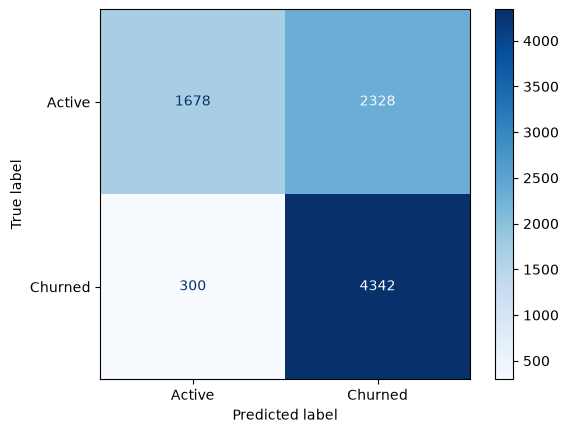

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

confusion_mat = confusion_matrix(y_test, y_pred)

print(confusion_mat)

ConfusionMatrixDisplay(confusion_mat, display_labels= ['Active', 'Churned']).plot(cmap= 'Blues')

**Reading the confusion matrix:** of 4,642 customers who really churned, the model caught **4,342** and missed only **300**. It also raised **2,328** false alarms among active customers: a retention call to a customer who would have stayed anyway. Missing a churner costs a customer's future orders; a false alarm costs one call, so high recall is the priority.

In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names= ['Active', 'Churned']))

              precision    recall  f1-score   support

      Active       0.85      0.42      0.56      4006
     Churned       0.65      0.94      0.77      4642

    accuracy                           0.70      8648
   macro avg       0.75      0.68      0.66      8648
weighted avg       0.74      0.70      0.67      8648



- All tuned models on the test data

For comparison only. The 12-feature rows are the tuned models before feature selection. Random Forest was chosen by CV F1 and the 10-feature version by the feature-selection CV; the test results are not used to change either choice.

In [43]:
test_results = []

for name, model_pipeline in tuned_models:

    test_pred = model_pipeline.predict(x_test)

    test_results.append({
        'Model': name + ' (12 features)',
        'CV F1': tuned_results.set_index('Model').loc[name, 'CV F1'],
        'Test F1': f1_score(y_test, test_pred),
        'Test Precision': precision_score(y_test, test_pred),
        'Test Recall': recall_score(y_test, test_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred)
    })

test_results.append({
    'Model': 'Random Forest (10 features, final)',
    'CV F1': selection_results.set_index('Features').loc[10, 'CV F1'],
    'Test F1': f1_score(y_test, y_pred),
    'Test Precision': precision_score(y_test, y_pred),
    'Test Recall': recall_score(y_test, y_pred),
    'Test Accuracy': accuracy_score(y_test, y_pred)
})

test_results.append({
    'Model': 'Baseline (flag everyone)',
    'CV F1': np.nan,
    'Test F1': f1_score(y_test, baseline_pred),
    'Test Precision': precision_score(y_test, baseline_pred),
    'Test Recall': recall_score(y_test, baseline_pred),
    'Test Accuracy': accuracy_score(y_test, baseline_pred)
})

test_results = pd.DataFrame(test_results)

(test_results.set_index('Model') * 100).round(2)

,CV F1,Test F1,Test Precision,Test Recall,Test Accuracy
Model,,,,,
Logistic Regression (12 features),81.63,76.19,64.99,92.05,69.11
Random Forest (12 features),82.07,76.65,64.97,93.43,69.44
XGBoost (12 features),81.90,76.91,65.13,93.90,69.74
"Random Forest (10 features, final)",81.98,76.77,65.10,93.54,69.61
Baseline (flag everyone),NaN,69.86,53.68,100.00,53.68


**Result:** all models clearly beat the baseline that flags every customer (+16 accuracy points), and the three tuned models are within one F1 point of each other: the features, not the algorithm, set the limit. The test F1 (about 77%) is lower than the CV F1 (about 82%) because the test months are just before Christmas, when fewer customers churn than in the training months.

### Fit Final Model to All Months

The test is finished. Refit the same settings on all ten months (December-September) for deployment; every row's 90-day answer is known by December 2011.

In [44]:
# Best settings from GridSearchCV
final_pipeline = Pipeline(steps= [('Preprocessing', make_preprocessing(selected_features)),
                                  ('Model', RandomForestClassifier(random_state= 42,
                                                                   n_estimators= 500,
                                                                   max_depth= 8,
                                                                   min_samples_leaf= 1,
                                                                   max_features= 'sqrt'))])

final_pipeline.fit(x[selected_features], y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['InvoiceCountLast365Days','PurchaseAmountLast365Days', 'DistinctProductCountLast365Days',...,'InvoiceCountLast90Days', 'PurchaseAmountLast90Days','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Num Pipeline 1', ...), ('Num Pipeline 2', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output,

- Feature Importance

In [45]:
feature_names = final_pipeline.named_steps['Preprocessing'].get_feature_names_out()

importance = pd.Series(final_pipeline.named_steps['Model'].feature_importances_,
                       index= [name.split('__')[-1] for name in feature_names]).sort_values()

px.bar(importance, orientation= 'h', title= 'Random Forest Feature Importance',
       labels= {'value': 'Importance', 'index': 'Feature'})

### Save Model

In [46]:
import joblib

joblib.dump(final_pipeline, 'models/churn_model.pkl')

['models/churn_model.pkl']

### Load Saved Model

In [47]:
model = joblib.load('models/churn_model.pkl')
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['InvoiceCountLast365Days','PurchaseAmountLast365Days', 'DistinctProductCountLast365Days',...,'InvoiceCountLast90Days', 'PurchaseAmountLast90Days','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Num Pipeline 1', ...), ('Num Pipeline 2', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output,

In [48]:
# Predict a few customers with the loaded model.
sample = x[selected_features].tail()

pd.DataFrame({
    'Predicted Churned': model.predict(sample),
    'Churn Probability': model.predict_proba(sample)[:, 1].round(3),
    'Actual Churned': y.tail()
})

,Predicted Churned,Churn Probability,Actual Churned
42827,1,0.811,1
42828,1,0.763,1
42829,0,0.299,0
42830,1,0.807,1
42831,0,0.494,0


In [49]:
# The loaded model must give exactly the same predictions as the fitted one.
(model.predict(x[selected_features]) == final_pipeline.predict(x[selected_features])).all()

np.True_

**Done.** The saved pipeline (`models/churn_model.pkl`) contains the preprocessing and the model together. The Streamlit app (`app.py`) loads it to score customers.